In [41]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats

from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [42]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [43]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [44]:
mask = '05'

In [45]:
icon = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_land_'+mask+'_2020-2050_30-60N_precip_count_sum.nc')['dry']
icon = icon[1:30,:]

In [46]:
#Define the yearly mean temperature change
data_path = Path('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/2020-2050/daily_tmean')
files = sorted([str(f) for f in data_path.glob(f'30-60N_ICON_ngc4008_daily_year_tmean_*.nc')])[:]
icon_tmean = xr.open_mfdataset(files, engine='netcdf4',combine='by_coords')['tas']
icon_tmean = icon_tmean[1:30,:]
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
icon_tmean_land = icon_tmean.where(land_sea_icon_zoom9 < 1, np.nan)
icon_tmean_land_mean = icon_tmean_land.mean(dim='cell').load()
icon_tmean_land_diff = icon_tmean_land_mean - icon_tmean_land_mean[0]

In [47]:
print(icon_tmean_land_diff.min())

<xarray.DataArray 'tas' ()>
array(-0.099998)


## ICON Cycle4

In [48]:
icon_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
icon_cycle4_land = xr.where(icon_cycle4_size < 1, 1, 0)
total_cells = icon_cycle4_land.sum()

percent_icon_cycle4 = icon / total_cells * 100  # DataArray of length time
percent_icon_cycle4_mean = percent_icon_cycle4.mean(dim='time')
icon_lin = stats.linregress(icon_tmean_land_mean,percent_icon_cycle4_mean)

print(icon_lin)

LinregressResult(slope=-0.27357268449753275, intercept=5.549482807048552, rvalue=-0.8248806786426744, pvalue=3.721641739379481e-08, stderr=0.036081450495256316, intercept_stderr=0.32356690382144193)


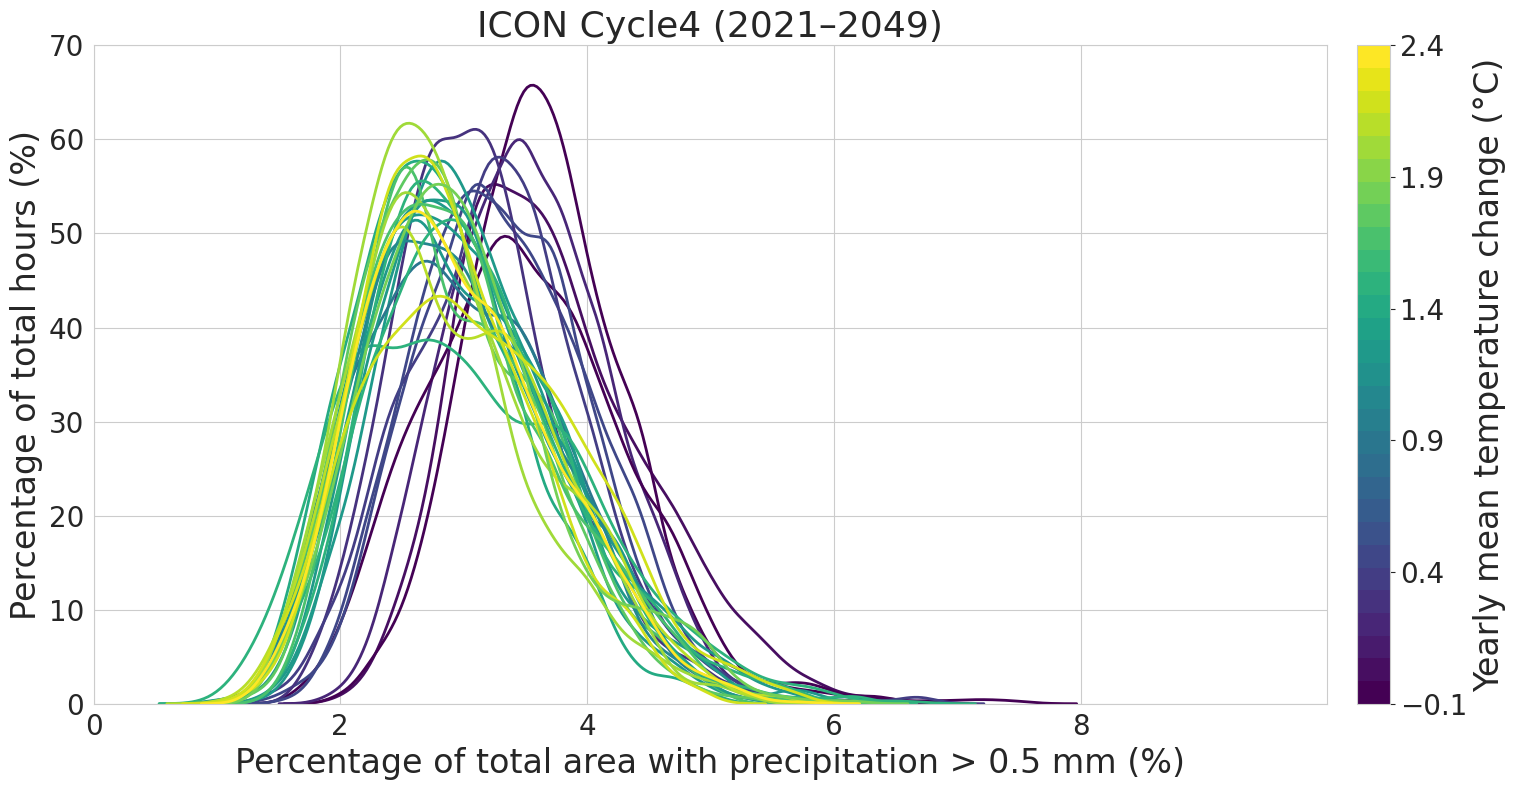

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 0, 25
bin_width = 1.0

# 2) Year indices (0–29) and number of years
years = percent_icon_cycle4.year.values
n_years = len(years)

# 3) Viridis colormap
temps = icon_tmean_land_diff.values
cmap = plt.get_cmap('viridis', n_years)

norm = plt.Normalize(
    vmin=-0.1,
    vmax=2.4
)

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = percent_icon_cycle4.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])
ticks = np.linspace(-0.1, 2.4, 6)

cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)


# 7) polish & save
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    xmin, xmax = 0, 10
plt.xlim(xmin, xmax)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

ax.set_xlabel(xl, fontsize=24)
ax.set_ylabel('Percentage of total hours (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)

plt.title('ICON Cycle4 (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_ICON_cycle4_histo_precip_coverage_'+mask+'_temp.pdf', format='pdf',bbox_inches='tight')

plt.show()
